
# Individual Assignment — Data Analysis with Pandas

## Overview
You will work individually using **two real‑world style datasets**:

1. Coffee Shop Sales Dataset — retail transactions analysis  
2. Ride Hailing Trips Dataset — transport service analysis  

The goal is to practice **beginner Pandas skills** in a meaningful way:
- Loading data
- Cleaning missing values
- Checking duplicates
- Creating new columns
- Sorting and grouping
- Datetime conversion
- Basic visualization

Write your answers using **code cells under each question**.


Omedi Alvin Eredi - 168560

In [2]:

import pandas as pd
import matplotlib.pyplot as plt



# Dataset 1 — Coffee Shop Sales

### Scenario
You are a data analyst working for a coffee chain. Management wants to understand:
- Sales trends
- Best‑selling products
- Revenue by location



## Question 1 — Data Cleaning
Convert Date to datetime.

Check:
- Missing values
- Duplicate TransactionID

Remove duplicates and fill missing City values with "Unknown".


In [3]:
# Convert Date to datetime.

# Check:
# - Missing values
# - Duplicate TransactionID

# Remove duplicates and fill missing City values with "Unknown".

df1 = pd.read_csv("Coffee_Shop_Sales.csv")
df1.head()


,TransactionID,Date,City,Product,Size,Quantity,UnitPrice_KES,PaymentMethod,Revenue_KES
0,CFE0250,2025-10-27,Mombasa,Latte,Large,1,324,Card,324
1,CFE0226,2025-03-04,Nairobi,Smoothie,Medium,3,430,Cash,1290
2,CFE0008,2025-04-03,Nakuru,Tea,Large,1,216,Card,216
3,CFE0189,2025-07-16,Kisumu,Espresso,Medium,1,415,M-Pesa,415
4,CFE0270,2026-01-28,Nakuru,Smoothie,Small,1,161,Cash,161


In [ ]:
#converting date to datetime
df1['Date'] = pd.to_datetime(df1['Date'])
#checking for missing values
print(df1.isnull().sum())
print('=='*20)
#checking for duplicate TransactionID
print(df1.duplicated(subset='TransactionID').sum())
df1 = df1.drop_duplicates(subset='TransactionID')
print('Duplicates removed. Current number of rows:', df1.shape[0])
p

TransactionID     0
Date              0
City             20
Product           0
Size              0
Quantity          0
UnitPrice_KES     0
PaymentMethod     0
Revenue_KES       0
dtype: int64
12
Duplicates removed. Current number of rows: 288


In [5]:
#fill missing City values with "Unknown"
df1['City'] = df1['City'].fillna('Unknown')
df1

,TransactionID,Date,City,Product,Size,Quantity,UnitPrice_KES,PaymentMethod,Revenue_KES
0,CFE0250,2025-10-27,Mombasa,Latte,Large,1,324,Card,324
1,CFE0226,2025-03-04,Nairobi,Smoothie,Medium,3,430,Cash,1290
2,CFE0008,2025-04-03,Nakuru,Tea,Large,1,216,Card,216
3,CFE0189,2025-07-16,Kisumu,Espresso,Medium,1,415,M-Pesa,415
4,CFE0270,2026-01-28,Nakuru,Smoothie,Small,1,161,Cash,161
...,...,...,...,...,...,...,...,...,...
295,CFE0103,2025-09-23,Kisumu,Mocha,Small,1,390,Cash,390
296,CFE0196,2025-06-03,Nakuru,Latte,Medium,3,211,Cash,633
297,CFE0168,2025-03-16,Unknown,Latte,Large,4,404,Cash,1616
298,CFE0294,2025-01-29,Eldoret,Tea,Small,4,420,Cash,1680



## Question 2 — Feature Engineering
Create:
- TotalRevenue_KES = Quantity × UnitPrice_KES
- Month extracted from Date


In [6]:
df1['TotalRevenue_KES'] = df1['Quantity'] * df1['UnitPrice_KES']
df1.head()

,TransactionID,Date,City,Product,Size,Quantity,UnitPrice_KES,PaymentMethod,Revenue_KES,TotalRevenue_KES
0,CFE0250,2025-10-27,Mombasa,Latte,Large,1,324,Card,324,324
1,CFE0226,2025-03-04,Nairobi,Smoothie,Medium,3,430,Cash,1290,1290
2,CFE0008,2025-04-03,Nakuru,Tea,Large,1,216,Card,216,216
3,CFE0189,2025-07-16,Kisumu,Espresso,Medium,1,415,M-Pesa,415,415
4,CFE0270,2026-01-28,Nakuru,Smoothie,Small,1,161,Cash,161,161


In [7]:
df1['Month'] = df1['Date'].dt.month
df1.head()

,TransactionID,Date,City,Product,Size,Quantity,UnitPrice_KES,PaymentMethod,Revenue_KES,TotalRevenue_KES,Month
0,CFE0250,2025-10-27,Mombasa,Latte,Large,1,324,Card,324,324,10
1,CFE0226,2025-03-04,Nairobi,Smoothie,Medium,3,430,Cash,1290,1290,3
2,CFE0008,2025-04-03,Nakuru,Tea,Large,1,216,Card,216,216,4
3,CFE0189,2025-07-16,Kisumu,Espresso,Medium,1,415,M-Pesa,415,415,7
4,CFE0270,2026-01-28,Nakuru,Smoothie,Small,1,161,Cash,161,161,1



## Question 3 — Sorting
Find the top 10 highest revenue transactions sorted descending.


In [9]:
top10_revenue = df1.sort_values(by= 'TotalRevenue_KES', ascending=False).head(10)
top10_revenue

,TransactionID,Date,City,Product,Size,Quantity,UnitPrice_KES,PaymentMethod,Revenue_KES,TotalRevenue_KES,Month
46,CFE0273,2025-03-25,Mombasa,Smoothie,Large,4,546,Cash,2184,2184,3
14,CFE0105,2025-02-14,Mombasa,Espresso,Medium,4,517,M-Pesa,2068,2068,2
162,CFE0284,2025-08-28,Nairobi,Cappuccino,Medium,4,511,Cash,2044,2044,8
168,CFE0112,2025-03-03,Nairobi,Cappuccino,Medium,4,506,Cash,2024,2024,3
69,CFE0267,2025-02-26,Mombasa,Espresso,Small,4,499,Card,1996,1996,2
105,CFE0015,2025-07-25,Nakuru,Espresso,Small,4,493,Cash,1972,1972,7
139,CFE0152,2025-12-15,Nairobi,Smoothie,Medium,4,470,Card,1880,1880,12
65,CFE0221,2025-08-07,Nairobi,Espresso,Large,4,470,Card,1880,1880,8
255,CFE0057,2025-12-06,Eldoret,Latte,Medium,4,467,M-Pesa,1868,1868,12
182,CFE0033,2025-07-29,Nairobi,Cappuccino,Medium,4,458,Cash,1832,1832,7



## Question 4 — GroupBy
Calculate total revenue by Product and City.
Which product performs best?


In [11]:
revenue_by_product_and_city = df1.groupby(['Product', 'City'])['TotalRevenue_KES'].sum().reset_index()
display (revenue_by_product_and_city)

,Product,City,TotalRevenue_KES
0,Cappuccino,Eldoret,10737
1,Cappuccino,Kisumu,5199
2,Cappuccino,Mombasa,7153
3,Cappuccino,Nairobi,10390
4,Cappuccino,Nakuru,10824
5,Cappuccino,Unknown,1996
6,Espresso,Eldoret,8476
7,Espresso,Kisumu,6506
8,Espresso,Mombasa,8609
9,Espresso,Nairobi,6318


In [18]:
best_product = revenue_by_product_and_city.groupby('Product')['TotalRevenue_KES'].sum().reset_index()
best_product = best_product.sort_values(by='TotalRevenue_KES', ascending=False).head()
best_product

,Product,TotalRevenue_KES
5,Tea,48240
4,Smoothie,47430
0,Cappuccino,46299
1,Espresso,40265
2,Latte,38160



## Question 5 — Visualization
Create a bar chart showing Total Revenue by Product.


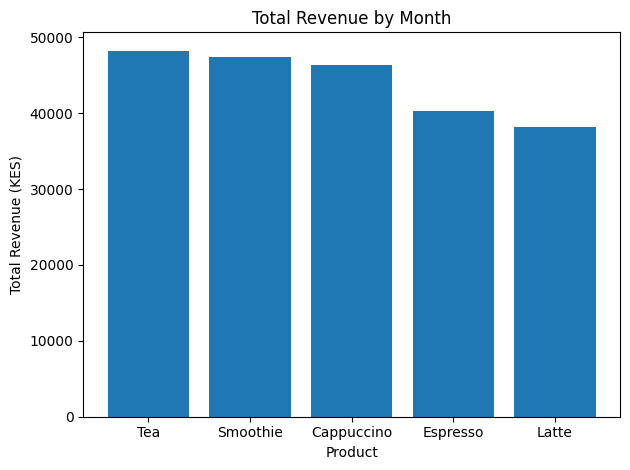

In [35]:
plt.title  ('Total Revenue by Month')
plt.xlabel('Product')
plt.ylabel('Total Revenue (KES)')
plt.bar(best_product['Product'], best_product['TotalRevenue_KES'])
# plt.xticks(rotation=15)
plt.tight_layout()

plt.show()


# Dataset 2 — Ride Hailing Trips

### Scenario
You are analyzing data for a ride‑hailing company.


In [20]:
df2 = pd.read_csv("Ride_Hailing_Trips.csv")
df2.head()

,TripID,TripDate,PickupCity,Distance_km,Duration_min,Fare_KES,DriverRating,PaymentType
0,TRP0287,2025-10-17,Kisumu,11.4,31,564,3.21,Card
1,TRP0019,2025-06-18,Nakuru,17.7,14,804,3.51,Card
2,TRP0242,2026-02-03,Mombasa,9.0,15,1097,4.81,Cash
3,TRP0017,2025-10-14,Mombasa,10.5,25,2446,3.48,Cash
4,TRP0251,2025-04-18,Nairobi,19.1,21,2302,NaN,M-Pesa



## Question 1 — Preparation
Convert TripDate to datetime.

Check:
- Missing DriverRating
- Duplicate TripID

Fill missing ratings with the average.


In [26]:
df2['TripDate'] = pd.to_datetime(df2['TripDate'])
print("=="*5, "Missing values in Ride_Hailing_Trips dataset", "=="*5)
print(df2.isnull().sum())
print("=="*5, "Duplicate TripID count", "=="*5)
print(df2.duplicated('TripID').sum())
df2 = df2.drop_duplicates(subset='TripID')
print('Duplicates removed. Current number of rows:', df2.shape[0])

========== Missing values in Ride_Hailing_Trips dataset ==========
TripID           0
TripDate         0
PickupCity       0
Distance_km      0
Duration_min     0
Fare_KES         0
DriverRating    17
PaymentType      0
dtype: int64
========== Duplicate TripID count ==========
0
Duplicates removed. Current number of rows: 290



## Question 2 — New Columns
Create:
- FarePerKm = Fare_KES / Distance_km
- TripHour extracted from TripDate


In [28]:
df2['FarePerKm'] = df2['Fare_KES'] / df2['Distance_km']
df2.head()

,TripID,TripDate,PickupCity,Distance_km,Duration_min,Fare_KES,DriverRating,PaymentType,FarePerKm
0,TRP0287,2025-10-17,Kisumu,11.4,31,564,3.21,Card,49.473684
1,TRP0019,2025-06-18,Nakuru,17.7,14,804,3.51,Card,45.423729
2,TRP0242,2026-02-03,Mombasa,9.0,15,1097,4.81,Cash,121.888889
3,TRP0017,2025-10-14,Mombasa,10.5,25,2446,3.48,Cash,232.952381
4,TRP0251,2025-04-18,Nairobi,19.1,21,2302,NaN,M-Pesa,120.523560


In [29]:
df2['TripHour'] = df2['TripDate'].dt.hour
df2.head()

,TripID,TripDate,PickupCity,Distance_km,Duration_min,Fare_KES,DriverRating,PaymentType,FarePerKm,TripHour
0,TRP0287,2025-10-17,Kisumu,11.4,31,564,3.21,Card,49.473684,0
1,TRP0019,2025-06-18,Nakuru,17.7,14,804,3.51,Card,45.423729,0
2,TRP0242,2026-02-03,Mombasa,9.0,15,1097,4.81,Cash,121.888889,0
3,TRP0017,2025-10-14,Mombasa,10.5,25,2446,3.48,Cash,232.952381,0
4,TRP0251,2025-04-18,Nairobi,19.1,21,2302,NaN,M-Pesa,120.523560,0


In [30]:
display(df2[['Fare_KES', 'Distance_km', 'FarePerKm', 'TripDate', 'TripHour']].head())

,Fare_KES,Distance_km,FarePerKm,TripDate,TripHour
0,564,11.4,49.473684,2025-10-17,0
1,804,17.7,45.423729,2025-06-18,0
2,1097,9.0,121.888889,2026-02-03,0
3,2446,10.5,232.952381,2025-10-14,0
4,2302,19.1,120.523560,2025-04-18,0



## Question 3 — Sorting
Find the longest 10 trips by Distance_km.


In [33]:
longest_distance_trip = df2.sort_values(by='Distance_km', ascending=False).head(10)
longest_distance_trip


,TripID,TripDate,PickupCity,Distance_km,Duration_min,Fare_KES,DriverRating,PaymentType,FarePerKm,TripHour
133,TRP0109,2025-08-28,Mombasa,24.8,11,784,3.74,Cash,31.612903,0
94,TRP0155,2025-12-29,Kisumu,24.8,10,1764,3.05,Card,71.129032,0
163,TRP0006,2025-09-25,Kisumu,24.8,29,294,3.89,Cash,11.854839,0
87,TRP0089,2025-08-15,Kisumu,24.8,30,445,3.42,Cash,17.943548,0
57,TRP0138,2025-12-27,Nairobi,24.8,24,607,4.95,Card,24.475806,0
250,TRP0073,2026-01-04,Nairobi,24.7,45,1574,4.98,M-Pesa,63.724696,0
105,TRP0056,2025-12-02,Nakuru,24.6,6,1183,3.71,M-Pesa,48.089431,0
253,TRP0009,2025-07-11,Nakuru,24.6,54,2045,4.05,Card,83.130081,0
200,TRP0299,2025-05-28,Mombasa,24.4,56,1255,NaN,Card,51.434426,0
146,TRP0078,2025-05-28,Kisumu,24.2,16,1104,3.65,Card,45.619835,0



## Question 4 — Group Analysis
Calculate average Fare_KES and DriverRating by PickupCity.


In [41]:
average_fare = df2.groupby('PickupCity')[['Fare_KES','DriverRating']].mean().reset_index()
average_fare

,PickupCity,Fare_KES,DriverRating
0,Kisumu,1493.763158,3.973472
1,Mombasa,1285.383721,4.036296
2,Nairobi,1236.484848,4.120952
3,Nakuru,1378.209677,3.954561



## Question 5 — Visualization
Create a bar chart showing Average Fare_KES by PickupCity.


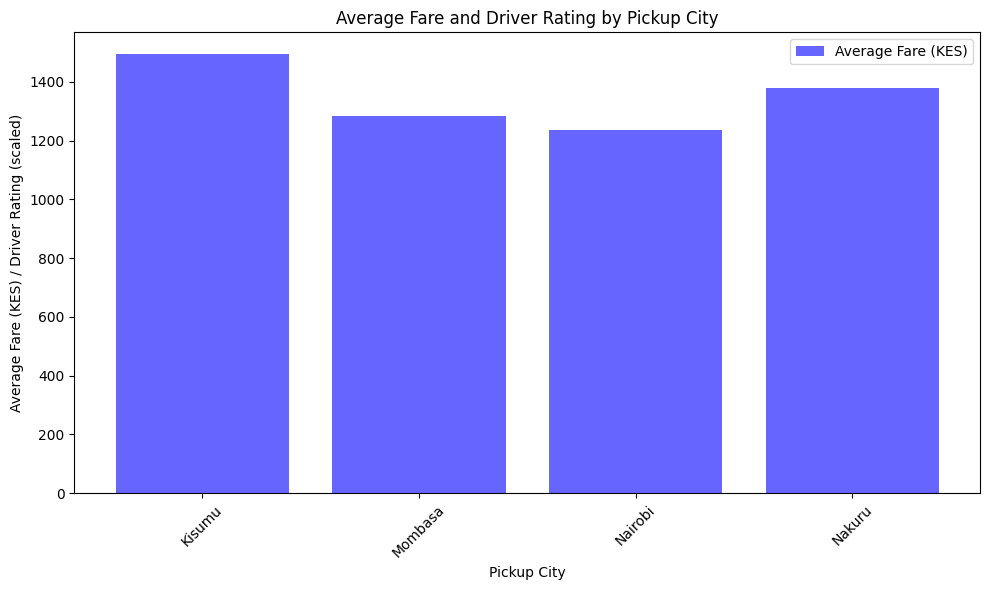

In [43]:
plt.figure(figsize=(10,6))
plt.title('Average Fare and Driver Rating by Pickup City')
plt.bar(average_fare['PickupCity'], average_fare['Fare_KES'], color='blue', alpha=0.6, label='Average Fare (KES)')
# plt.bar(average_fare['PickupCity'], average_fare['DriverRating']*20, color='orange', alpha=0.6, label='Average Driver Rating (scaled)')
plt.xlabel('Pickup City')   
plt.ylabel('Average Fare (KES) / Driver Rating (scaled)')
plt.xticks(rotation=45)
plt.legend()
plt.tight_layout()
plt.show()